# 02 · Network data audit (agaar.gov.mn, Ulaanbaatar, winter 2025/26)

**Goal:** decide which stations enter the network-design experiment and lock the event threshold.

**Needs:** the agaar archive copied from data-mn into `data/raw/agaar/`
(`agaar-stations.csv` and `daily/agaar-daily-YYYY-MM.csv`).
Daily files are used, not hourly: the site deletes hourly concentrations once a month is validated.

Logic: `src/uaq/agaar.py` (loading + cleaning) and `src/uaq/audit_network.py`.

In [1]:
# Setup: works whether or not you ran `pip install -e .`
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
cfg = load_config()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


In [2]:
display(pd.DataFrame(cfg["network"]["split"]).T.rename_axis("split"))
print("Cleaning rules:", cfg["network"]["cleaning"])

,start,end
split,,
train,2025-10-01,2025-12-31
val,2026-01-01,2026-01-31
test,2026-02-01,2026-03-31


Cleaning rules: {'above_pm10_ratio': 1.1, 'above_pm10_min': 50, 'spike_ratio': 5, 'spike_min': 150, 'flat_days': 5}


## 1 · Load and clean
Same rules as data-mn's own build: drop negative values, PM2.5 above PM10, spikes (>5× that day's cross-station median and >150), and stuck sensors (same value 5+ days).

In [3]:
from uaq import audit_network as an
r = an.prepare(cfg)
daily, stations = r["daily"], r["stations"]
print("Station-days by cleaning outcome:")
display(daily["dropped_reason"].replace("", "kept").value_counts().to_frame("station-days"))
names = stations.set_index("station_code")["name_mn"]
stations

Station-days by cleaning outcome:


,station-days
dropped_reason,
kept,6925
above_pm10,80
spike,17
flat,6
negative,2


,station_code,name_mn,lat,lon
0,12301,Бөхийн өргөө,47.917550,106.937478
1,12303,Ургах наран,47.866467,107.118775
2,12304,Шархад,47.933744,107.010403
3,12305,Амгалан-3,47.913503,106.997911
4,12306,Шинэ 100 айл төв,47.904450,106.980743
5,12401,1-р хороолол,47.918069,106.847819
6,12402,Толгойт-1,47.922489,106.794842
7,12403,Баянхошуу-6,47.863956,106.931942
8,12404,5 Шар,47.912121,106.814642
9,12501,100 айл,47.932892,106.921361


## 2 · Coverage by split → eligible stations
A station is eligible with ≥75% valid days in train **and** validation **and** test.

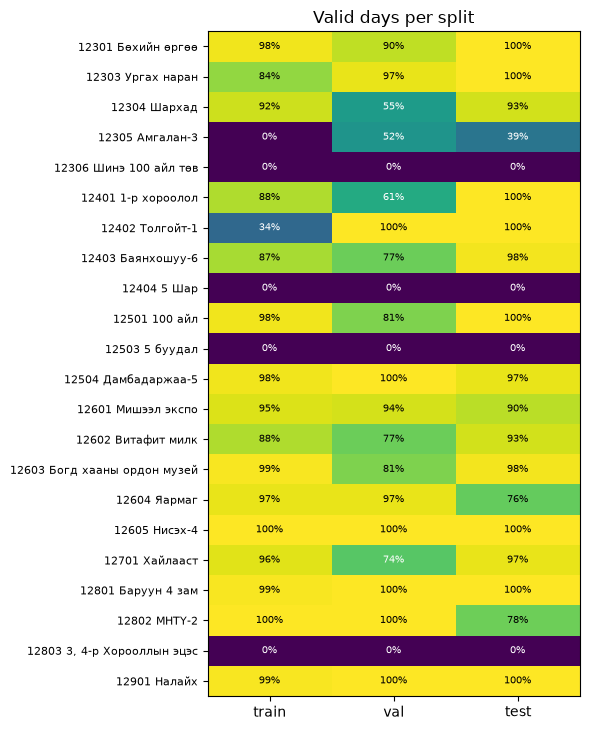

13 eligible: ['12301', '12303', '12403', '12501', '12504', '12601', '12602', '12603', '12604', '12605', '12801', '12802', '12901']


In [4]:
an.plot_coverage(r["coverage"], names, cfg["quality"]["min_valid_frac"]); plt.show()
print(len(r["eligible"]), "eligible:", r["eligible"])

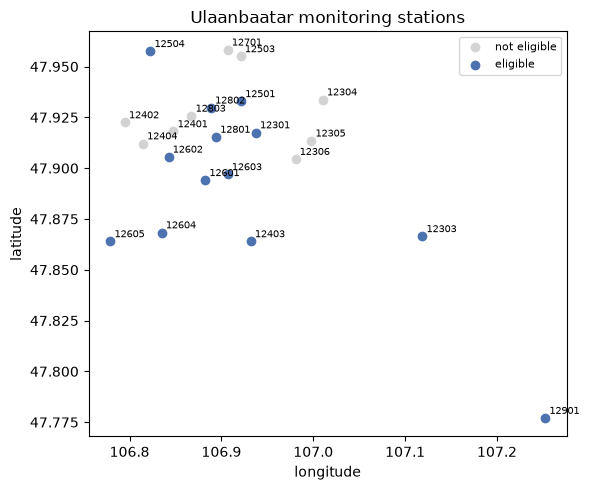

In [5]:
an.plot_map(stations, r["eligible"]); plt.show()

## 3 · The winter in one picture
City median and the range across eligible stations, with the splits shaded. Note the validation month (January) is the most polluted; the test months (Feb–Mar) are cleaner.

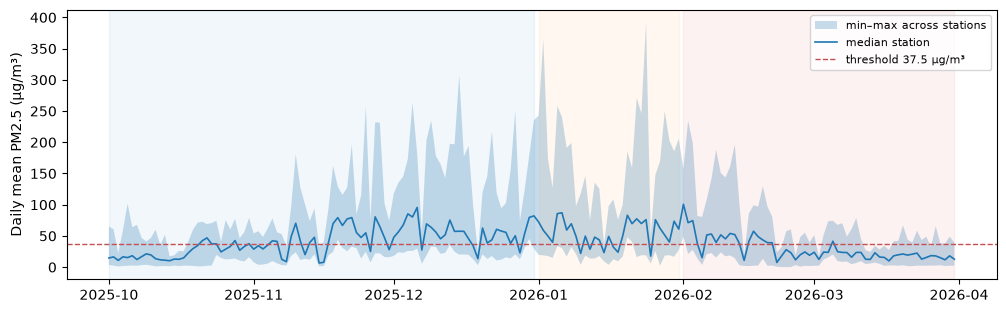

In [6]:
w = r["wide"]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(w.index, w.min(axis=1), w.max(axis=1), alpha=0.25, label="min–max across stations")
ax.plot(w.index, w.median(axis=1), lw=1.2, label="median station")
ax.axhline(r["threshold"], color="#C44E52", ls="--", lw=1, label=f"threshold {r['threshold']} µg/m³")
for name, s in cfg["network"]["split"].items():
    ax.axvspan(pd.Timestamp(s["start"]), pd.Timestamp(s["end"]), alpha=0.06, color={"train": "C0", "val": "C1", "test": "C3"}[name])
ax.set_ylabel("Daily mean PM2.5 (µg/m³)"); ax.legend(fontsize=8); plt.show()

## 4 · How redundant are the stations?
High correlation between stations is what makes a smaller network possible, and what makes the choice non-trivial: the best set avoids keeping near-duplicates.

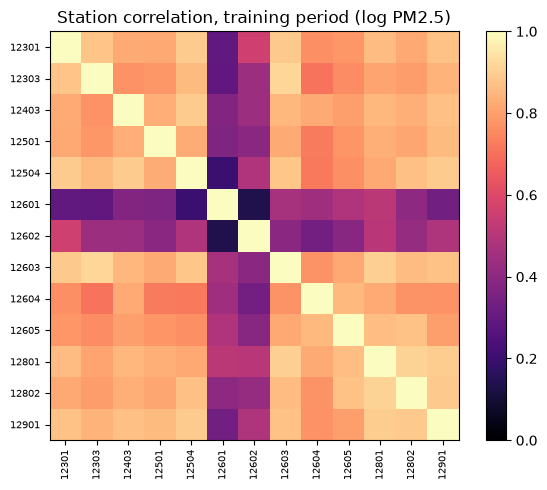

In [7]:
an.plot_correlation(r["wide"], r["masks"]["train"]); plt.show()

**Check before trusting the GA:** a station that correlates weakly with every other one is either a genuinely different micro-environment (worth keeping) or a faulty sensor (should be excluded). Plot any such station against the city median below and decide; record the decision in the report.

,mean correlation with other stations
station_code,
12601,0.36
12602,0.42
12604,0.71
12501,0.74
12303,0.74


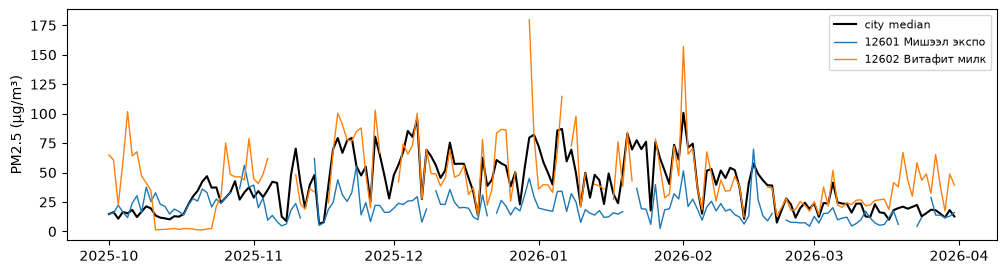

In [8]:
corr = np.log1p(r["wide"][r["masks"]["train"]]).corr()
mean_corr = (corr.sum() - 1) / (len(corr) - 1)
display(mean_corr.sort_values().round(2).to_frame("mean correlation with other stations").head(5))
odd = mean_corr.nsmallest(2).index.tolist()
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(r["wide"].index, r["wide"].median(axis=1), color="k", lw=1.5, label="city median")
for c in odd:
    ax.plot(r["wide"].index, r["wide"][c], lw=1, label=f"{c} {names[c]}")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(fontsize=8); plt.show()

## 5 · Event threshold (training station-days)

In [9]:
display(r["rates"].round(3))
print(f"Chosen: {r['threshold_name']} = {r['threshold']} µg/m³\n{r['threshold_why']}")

,threshold,ug_m3,base_rate
0,mns_4585_2025,37.5,0.485
1,mns_4585_2016,50.0,0.351
2,who_it1_2021,75.0,0.169
3,train_p75,61.3,0.250


Chosen: mns_4585_2025 = 37.5 µg/m³
Lowest official threshold exceeded on ≤ 60% of training days (rates: mns_4585_2025 48%).


## 6 · Save the audit report

In [10]:
report = an.run()
print(report.read_text()[:1500])

# Network data audit (agaar.gov.mn, Ulaanbaatar)

- Daily files read: 21
- Ulaanbaatar stations in catalogue: 22
- Station-days by cleaning outcome: {'kept': 6925, 'above_pm10': 80, 'spike': 17, 'flat': 6, 'negative': 2}

## Decisions

- **Eligible stations:** 13 (≥75% valid days in train, val AND test) → 12301, 12303, 12403, 12501, 12504, 12601, 12602, 12603, 12604, 12605, 12801, 12802, 12901
- **Exhaustive search feasible for every k:** yes
- **Event threshold:** mns_4585_2025 = 37.5 µg/m³. Lowest official threshold exceeded on ≤ 60% of training days (rates: mns_4585_2025 48%).
- **Splits:** train 2025-10-01→2025-12-31, val 2026-01-01→2026-01-31, test 2026-02-01→2026-03-31 (sealed).

## Coverage by split

|   station_code |   train |   val |   test | name                   |
|---------------:|--------:|------:|-------:|:-----------------------|
|          12301 |    0.98 |  0.90 |   1.00 | Бөхийн өргөө           |
|          12303 |    0.84 |  0.97 |   1.00 | Ургах наран            |